# Session 10

A small 2-layer GPT on TinyStories. Results are in README.md.

## Setup

In [1]:
%%writefile data_pipeline.py
import os
import glob

import numpy as np
from tokenizers import ByteLevelBPETokenizer


class Tokenizer:
    def __init__(self, bpe_dir="data/bpe"):
        self.bpe = ByteLevelBPETokenizer(os.path.join(bpe_dir, "vocab.json"),
                                         os.path.join(bpe_dir, "merges.txt"))
        n = self.bpe.get_vocab_size()
        self.PAD = n
        self.EOS = n + 1
        self.V = n + 2


class Config:
    def __init__(self):
        self.TOK = Tokenizer()
        self.V = self.TOK.V   # vocab size
        self.T = 256          # context length
        self.D = 256          # model dimension
        self.H = 8            # heads
        self.HD = self.D // self.H   # head dimension
        self.DFF = self.D * 4        # feed-forward dimension
        self.L = 2            # layers


class ShardStream:
    """Reads token shards into RAM and gives (tokens, doc_id) batches."""

    def __init__(self, split_dir, B, T, seed=0, max_tokens=None, max_shards=None,
                 rank=0, world_size=1):
        paths = sorted(glob.glob(os.path.join(split_dir, "shard_*.tok.npy")))
        if max_shards is not None:                 # None = all shards; int = first N
            paths = paths[:max_shards]
        if not paths:
            raise SystemExit(f"no shards in {split_dir}/")

        toks, docs, have = [], [], 0
        for p in paths:                            # stop once the budget is met
            if max_tokens is not None and have >= max_tokens:
                break
            toks.append(np.load(p))
            docs.append(np.load(p.replace(".tok.npy", ".doc.npy")))
            have += len(toks[-1])
        self.toks = np.concatenate(toks)
        self.docs = np.concatenate(docs)
        if max_tokens is not None:                 # trim to the exact budget
            self.toks = self.toks[:max_tokens]
            self.docs = self.docs[:max_tokens]

        self.B, self.T = B, T
        self.rank, self.world_size = rank, world_size
        self.rng = np.random.default_rng(seed)     # SHARED across ranks (same seed)
        self.n_blocks = len(self.toks) // T        # global block id runs 0..n_blocks-1
        self.offsets = np.arange(T)
        print(f"{split_dir}: {len(toks)} shards, {len(self.toks):,} tokens, "
              f"{self.n_blocks:,} blocks", flush=True)

    def _batch(self, block_ids):
        idx = block_ids[:, None] * self.T + self.offsets   # (B, T) positions
        return self.toks[idx].astype(np.int64), self.docs[idx].astype(np.int64)

    def epoch(self):
        order = self.rng.permutation(self.n_blocks)      # same on all ranks (shared seed)
        mine = order[self.rank::self.world_size]          # disjoint stride partition
        for i in range(0, len(mine) - self.B + 1, self.B):
            yield self._batch(mine[i:i + self.B])         # one vectorized gather

    def iter_batches(self):
        while True:
            yield from self.epoch()

Writing data_pipeline.py


In [2]:
%%writefile transformer.py
import torch
import torch.nn as nn
import torch.nn.functional as F

from data_pipeline import Tokenizer

_TOK = None

def make_masks(tokens,doc_id):
    global _TOK
    if _TOK is None:
        _TOK = Tokenizer()          # first call only; cached thereafter
    TOK = _TOK
    B,T = tokens.shape
    # no peeking into future tokens
    causal = torch.tril(torch.ones(T,T, dtype=torch.bool, device=tokens.device)) # (T,T)
    # only attend to tokens within the same document
    same = doc_id[:,:,None] == doc_id[:,None,:] # (B,T,1) vs (B,1,T) -> (B,T,T)
    # combine causal and same-document masks
    attn = (causal & same).unsqueeze(1) # (B,1,T,T)
    # target tokens (shifted by one)
    tgt = tokens[:,1:]
    # identify positions where the document changes
    join = doc_id[:,1:] != doc_id[:,:-1] # (B,T-1) vs (B,T-1) -> comparing adjacent doc_ids
    # positions where the document changes (to avoid computing loss across document boundaries)
    loss = (tgt != TOK.PAD) & (~join)
    return attn, loss

class RMSNorm(nn.Module):
    def __init__(self,d):
        super().__init__()
        self.d = d
        self.g = nn.Parameter(torch.ones(d))
    def forward(self,x):
        # RMSNorm forward pass
        ms = x.pow(2).mean(-1, keepdim=True) # (B,T,D) -> (B,T,1)
        return x*torch.rsqrt(ms + 1e-6)*self.g

class Attention(nn.Module):
    def __init__(self,c):
        super().__init__()
        self.c = c
        self.q = nn.Linear(c.D, c.D, bias=False)
        self.k = nn.Linear(c.D, c.D, bias=False)
        self.v = nn.Linear(c.D, c.D, bias=False)
        self.out = nn.Linear(c.D, c.D, bias=False)
    def forward(self,x,mask):
        c  = self.c
        B,T,_ = x.shape
        sp = lambda t: t.view(B,T,c.H, c.HD).transpose(1,2)
        # get q,k,v projections for multi-head attention
        q,k,v = sp(self.q(x)), sp(self.k(x)), sp(self.v(x)) # (B,c.H,T,c.HD)
        # multiply queries and keys to get attention scores
        s = (q @ k.transpose(-2,-1)) / (c.HD ** 0.5) # (B,c.H,T,c.HD) @ (B,c.H,c.HD,T) -> (B,c.H,T,T)
        # apply the attention mask to prevent attending to future tokens or tokens from different documents
        s = s.masked_fill(~mask, float('-inf'))
        # softmax to obtain attention weights
        w = torch.nan_to_num(s.softmax(-1))
        # value vectors are combined with attention weights to produce the context vectors
        ctx = (w @ v).transpose(1,2).reshape(B,T,c.D) 
        return self.out(ctx)

class SwiGLU(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.gate = nn.Linear(c.D, c.DFF, bias=False)
        self.up = nn.Linear(c.D, c.DFF, bias=False)
        self.bottom = nn.Linear(c.DFF, c.D, bias=False)
    def forward(self,x):
        return self.bottom(self.up(x) * F.silu(self.gate(x)))

class Block(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.c = c
        self.attn = Attention(c)
        self.n1 = RMSNorm(c.D)
        self.n2 = RMSNorm(c.D)
        self.ffn = SwiGLU(c)
    def forward(self,x,mask):
        x = x + self.attn(self.n1(x), mask)
        x = x + self.ffn(self.n2(x))
        return x

class GPT(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.c = c
        self.tok_emb = nn.Embedding(c.V, c.D)
        self.pos_emb = nn.Embedding(c.T, c.D)
        self.blocks = nn.ModuleList([Block(c) for _ in range(c.L)])
        self.ns = RMSNorm(c.D)
        self.head = nn.Linear(c.D, c.V, bias=False)

    def forward(self,tokens, mask):
        B,T = tokens.shape
        pos = torch.arange(T, device=tokens.device)
        x = self.tok_emb(tokens) + self.pos_emb(pos)
        for blk in self.blocks:
            x = blk(x,mask)
        x = self.ns(x)
        logits = self.head(x)
        return logits

def loss_fn(logits, tokens, loss_mask):
    tgt = tokens[:, 1:].reshape(-1) # (B, T-1) -> (B*(T-1))
    lg = logits[:,:-1].reshape(-1,logits.size(-1)) # (B, T-1, V) -> (B*(T-1), V)
    nll = F.cross_entropy(lg, tgt, reduction='none')
    m = loss_mask.reshape(-1).float()
    loss = (nll * m).sum() / m.sum().clamp(min=1)
    return loss, int(m.sum())

def _trace_shapes(model, tokens, doc_id):
    """One-time forward pass that prints the output shape of every submodule."""
    attn, loss_mask = make_masks(tokens, doc_id)
    print("  inputs:")
    print(f"    {'tokens':<26} {tuple(tokens.shape)}")
    print(f"    {'doc_id':<26} {tuple(doc_id.shape)}")
    print(f"    {'attn mask':<26} {tuple(attn.shape)}")
    print(f"    {'loss mask':<26} {tuple(loss_mask.shape)}")
    print("  module outputs:")

    handles = []
    def mk(name):
        def hook(mod, inp, out):
            if isinstance(out, torch.Tensor):
                print(f"    {name:<26} {tuple(out.shape)}")
        return hook
    for name, mod in model.named_modules():
        if name:                                     # skip the root module
            handles.append(mod.register_forward_hook(mk(name)))
    with torch.no_grad():
        logits = model(tokens, attn)
    for h in handles:
        h.remove()
    print(f"    {'logits (head)':<26} {tuple(logits.shape)}")

Writing transformer.py


In [3]:
import os, time, math
from fractions import Fraction

import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

SHARD_ROOT = "/kaggle/input/datasets/gona26/tinystories-data-540m/shards"
BPE_SRC = "/kaggle/input/datasets/gona26/tinystories-data-540m/bpe"

os.makedirs("data", exist_ok=True)
os.makedirs("results", exist_ok=True)
if not os.path.lexists("data/bpe"):
    os.symlink(BPE_SRC, "data/bpe")

from data_pipeline import Config, ShardStream
from transformer import GPT, make_masks, loss_fn, _trace_shapes

dev = "cuda" if torch.cuda.is_available() else "cpu"
cfg = Config()

B = 4
LENGTHS = [256, 96, 32, 8]
STEPS = 300

def to_t(x, d):
    return (torch.from_numpy(np.ascontiguousarray(x)).to(dev),
            torch.from_numpy(np.ascontiguousarray(d)).to(dev))

def build_steps(n_steps, lengths, seed=0):
    # each step is a list of micro-batches, one per length
    stream = ShardStream(f"{SHARD_ROOT}/train", B=B, T=cfg.T, seed=seed,
                         max_tokens=500_000).iter_batches()
    out = []
    for _ in range(n_steps):
        mbs = []
        for t in lengths:
            x, d = next(stream)
            mbs.append((x[:, :t], d[:, :t]))
        out.append(mbs)
    return out

steps = build_steps(STEPS, LENGTHS)

/kaggle/input/datasets/gona26/tinystories-data-540m/shards/train: 1 shards, 500,000 tokens, 1,953 blocks


## Part 1: tensor shapes

In [4]:
model = GPT(cfg).to(dev)
print(model)
_trace_shapes(model, *to_t(*steps[0][0]))

GPT(
  (tok_emb): Embedding(4002, 256)
  (pos_emb): Embedding(256, 256)
  (blocks): ModuleList(
    (0-1): 2 x Block(
      (attn): Attention(
        (q): Linear(in_features=256, out_features=256, bias=False)
        (k): Linear(in_features=256, out_features=256, bias=False)
        (v): Linear(in_features=256, out_features=256, bias=False)
        (out): Linear(in_features=256, out_features=256, bias=False)
      )
      (n1): RMSNorm()
      (n2): RMSNorm()
      (ffn): SwiGLU(
        (gate): Linear(in_features=256, out_features=1024, bias=False)
        (up): Linear(in_features=256, out_features=1024, bias=False)
        (bottom): Linear(in_features=1024, out_features=256, bias=False)
      )
    )
  )
  (ns): RMSNorm()
  (head): Linear(in_features=256, out_features=4002, bias=False)
)
  inputs:
    tokens                     (4, 256)
    doc_id                     (4, 256)
    attn mask                  (4, 1, 256, 256)
    loss mask                  (4, 255)
  module outputs:
  

In [5]:
# the hooks above can't see inside attention or the loss, so walk one step by hand
def trace_step(model, x, d):
    c = model.c
    def show(name, t, meaning):
        print(f"{name:<22} {str(tuple(t.shape)):<20} {meaning}")

    tokens, doc = to_t(x, d)
    B, T = tokens.shape
    attn, loss_mask = make_masks(tokens, doc)
    show("tokens", tokens, "B sequences, T token ids")
    show("doc_id", doc, "B sequences, T doc ids")
    show("attn mask", attn, "B, 1 copied across H, T, T")
    show("loss mask", loss_mask, "B, T-1 predictions")

    pos = torch.arange(T, device=tokens.device)
    tok, pe = model.tok_emb(tokens), model.pos_emb(pos)
    h = tok + pe
    show("tok_emb", tok, "B, T, D")
    show("pos_emb", pe, "T, D; no B, shared by all sequences")

    blk, a = model.blocks[0], model.blocks[0].attn
    sp = lambda t: t.view(B, T, c.H, c.HD).transpose(1, 2)
    n1 = blk.n1(h)
    q, k, v = sp(a.q(n1)), sp(a.k(n1)), sp(a.v(n1))
    s = (q @ k.transpose(-2, -1)) / (c.HD ** 0.5)
    w = torch.nan_to_num(s.masked_fill(~attn, float("-inf")).softmax(-1))
    mix = w @ v
    ctx = mix.transpose(1, 2).reshape(B, T, c.D)
    show("q, k, v", q, "B, H, T, HD; D split across heads")
    show("attn scores", s, "B, H, T, T; token vs token")
    show("attn weights", w, "B, H, T, T; each row sums to 1")
    show("mixed values", mix, "B, H, T, HD")
    show("ctx", ctx, "B, T, D; heads joined back")

    n2 = blk.n2(h + a.out(ctx))
    up = blk.ffn.up(n2)
    show("ffn up", up, "B, T, DFF")

    logits = model(tokens, attn)
    show("logits", logits, "B, T, V")

    tgt = tokens[:, 1:].reshape(-1)
    lg = logits[:, :-1].reshape(-1, logits.size(-1))
    nll = F.cross_entropy(lg, tgt, reduction="none")
    m = loss_mask.reshape(-1).float()
    loss = (nll * m).sum() / m.sum().clamp(min=1)
    show("flat logits", lg, "B*(T-1), V")
    show("flat targets", tgt, "B*(T-1)")
    show("token losses", nll, "B*(T-1)")
    show("loss", loss, "one number")

    model.zero_grad(set_to_none=True)
    loss.backward()
    show("head.weight", model.head.weight, "V, D")
    show("head.weight.grad", model.head.weight.grad, "V, D; one slope per weight")

trace_step(GPT(cfg).to(dev), *steps[0][1])

tokens                 (4, 96)              B sequences, T token ids
doc_id                 (4, 96)              B sequences, T doc ids
attn mask              (4, 1, 96, 96)       B, 1 copied across H, T, T
loss mask              (4, 95)              B, T-1 predictions
tok_emb                (4, 96, 256)         B, T, D
pos_emb                (96, 256)            T, D; no B, shared by all sequences
q, k, v                (4, 8, 96, 32)       B, H, T, HD; D split across heads
attn scores            (4, 8, 96, 96)       B, H, T, T; token vs token
attn weights           (4, 8, 96, 96)       B, H, T, T; each row sums to 1
mixed values           (4, 8, 96, 32)       B, H, T, HD
ctx                    (4, 96, 256)         B, T, D; heads joined back
ffn up                 (4, 96, 1024)        B, T, DFF
logits                 (4, 96, 4002)        B, T, V
flat logits            (380, 4002)          B*(T-1), V
flat targets           (380,)               B*(T-1)
token losses           (380,)     

## Part 2: one gradient by hand

In [6]:
# float64 model on the same device as the data
torch.manual_seed(0)
model = GPT(cfg).double().to(dev)

# one fixed micro-batch, reused for every measurement
x, d = steps[0][1]
tokens, doc = to_t(x, d)
attn, mask = make_masks(tokens, doc)

# pick one weight to nudge
pname, i = "head.weight", 5                # parameter name, flat index into it
p = dict(model.named_parameters())[pname]
w = p.data.view(-1)                        # view that shares memory with the parameter
orig = w[i].item()
print(f"nudging {pname}[{i}], original value = {orig:.12e}")

# loss at the current weights, then backward() for the gradient it reports
loss, _ = loss_fn(model(tokens, attn), tokens, mask)
model.zero_grad()
loss.backward()
analytic = p.grad.view(-1)[i].item()
print(f"loss at original      = {loss.item():.12f}")
print(f"backward() gradient   = {analytic:.12e}")

# nudge the weight by +eps, measure the loss, restore
eps = 1e-6
with torch.no_grad():
    w[i] = orig + eps
    loss_plus = loss_fn(model(tokens, attn), tokens, mask)[0].item()
    w[i] = orig
print(f"loss with w + eps     = {loss_plus:.12f}")

# nudge by -eps, measure, restore
with torch.no_grad():
    w[i] = orig - eps
    loss_minus = loss_fn(model(tokens, attn), tokens, mask)[0].item()
    w[i] = orig
print(f"loss with w - eps     = {loss_minus:.12f}")

# the slope from the nudges, compared with backward()
numeric = (loss_plus - loss_minus) / (2 * eps)
print(f"finite-diff gradient  = {numeric:.12e}")
print(f"difference            = {abs(analytic - numeric):.2e}")

nudging head.weight[5], original value = 1.221929490566e-02
loss at original      = 8.482925585863
backward() gradient   = 2.064077989812e-04
loss with w + eps     = 8.482925586069
loss with w - eps     = 8.482925585657
finite-diff gradient  = 2.064073356678e-04
difference            = 4.63e-10


## Part 3: breaking gradient accumulation

In [7]:
def step_correct(model, opt, mbs):
    # every token counts the same
    opt.zero_grad()
    tok_total, loss_sum = 0, 0.0
    for x, d in mbs:
        tokens, doc = to_t(x, d)
        attn, mask = make_masks(tokens, doc)
        loss, n = loss_fn(model(tokens, attn), tokens, mask)
        (loss * n).backward()
        tok_total += n
        loss_sum += loss.item() * n
    for p in model.parameters():
        if p.grad is not None:
            p.grad /= tok_total
    return loss_sum / tok_total

def step_avg_of_avgs(model, opt, mbs):
    # every micro-batch counts the same (the bug)
    opt.zero_grad()
    losses = []
    for x, d in mbs:
        tokens, doc = to_t(x, d)
        attn, mask = make_masks(tokens, doc)
        loss, _ = loss_fn(model(tokens, attn), tokens, mask)
        (loss / len(mbs)).backward()
        losses.append(loss.item())
    return sum(losses) / len(losses)

@torch.no_grad()
def eval_loss(model, tokens, doc):
    attn, mask = make_masks(tokens, doc)
    return loss_fn(model(tokens, attn), tokens, mask)[0].item()

def run_tracked(step_fn, init_state, steps, eval_tokens, eval_doc, lr=3e-4):
    # columns: step, train loss, grad norm, loss on one fixed batch
    model = GPT(cfg).to(dev)
    model.load_state_dict(init_state)
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    rows = []
    for s, mbs in enumerate(steps):
        fixed = eval_loss(model, eval_tokens, eval_doc)
        loss = step_fn(model, opt, mbs)
        gn = torch.nn.utils.clip_grad_norm_(model.parameters(), float("inf")).item()
        opt.step()
        rows.append((s, loss, gn, fixed))
    return np.array(rows)

def fixed_batch(split, B_eval, seed=123, max_tokens=200_000):
    stream = ShardStream(f"{SHARD_ROOT}/{split}", B=B_eval, T=cfg.T, seed=seed,
                         max_tokens=max_tokens).iter_batches()
    return to_t(*next(stream))

/kaggle/input/datasets/gona26/tinystories-data-540m/shards/val: 1 shards, 200,000 tokens, 781 blocks
/kaggle/input/datasets/gona26/tinystories-data-540m/shards/train: 1 shards, 500,000 tokens, 1,953 blocks
seed 0: correct 4.394 | avg of avgs 4.675 | gap +0.282
/kaggle/input/datasets/gona26/tinystories-data-540m/shards/train: 1 shards, 500,000 tokens, 1,953 blocks
seed 1: correct 4.379 | avg of avgs 4.669 | gap +0.289
/kaggle/input/datasets/gona26/tinystories-data-540m/shards/train: 1 shards, 500,000 tokens, 1,953 blocks
seed 2: correct 4.380 | avg of avgs 4.650 | gap +0.270


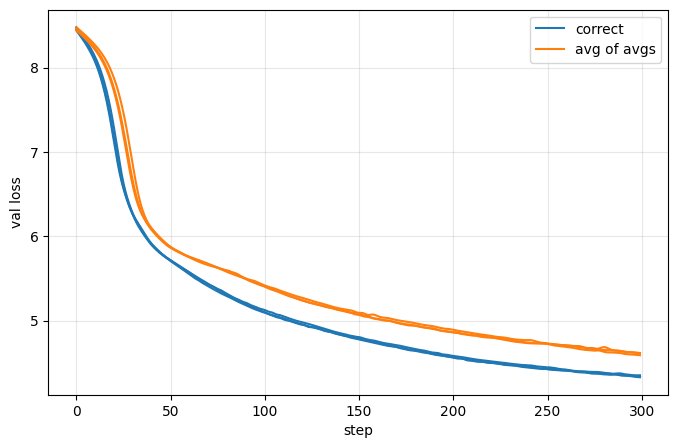

seed spread: 0.007
/kaggle/input/datasets/gona26/tinystories-data-540m/shards/train: 1 shards, 500,000 tokens, 1,953 blocks
control, largest difference: 1.1920928955078125e-05


In [8]:
# train both ways from the same start, score both on the same val batch
val_tok, val_doc = fixed_batch("val", 32)

fair = {}
fig, ax = plt.subplots(figsize=(8, 5))
for seed in [0, 1, 2]:
    torch.manual_seed(seed)
    init = GPT(cfg).to(dev).state_dict()
    st = build_steps(STEPS, LENGTHS, seed=seed)
    rc = run_tracked(step_correct, init, st, val_tok, val_doc)
    ra = run_tracked(step_avg_of_avgs, init, st, val_tok, val_doc)
    fair[seed] = (rc, ra)
    ax.plot(rc[:, 0], rc[:, 3], color="tab:blue", label="correct" if seed == 0 else None)
    ax.plot(ra[:, 0], ra[:, 3], color="tab:orange", label="avg of avgs" if seed == 0 else None)
    c, a = rc[250:, 3].mean(), ra[250:, 3].mean()
    print(f"seed {seed}: correct {c:.3f} | avg of avgs {a:.3f} | gap {a - c:+.3f}")

ax.set_xlabel("step"); ax.set_ylabel("val loss"); ax.legend(); ax.grid(alpha=0.3)
fig.savefig("results/accumulation_fair.png", dpi=120, bbox_inches="tight")
plt.show()

print("seed spread:", round(float(np.std([fair[s][0][250:, 3].mean() for s in fair])), 3))

# control: equal lengths, so both methods should match
torch.manual_seed(0)
init = GPT(cfg).to(dev).state_dict()
st = build_steps(STEPS, [64, 64, 64, 64], seed=0)
rc = run_tracked(step_correct, init, st, val_tok, val_doc)
ra = run_tracked(step_avg_of_avgs, init, st, val_tok, val_doc)
print("control, largest difference:", float(np.abs(rc[:, 3] - ra[:, 3]).max()))

## Part 4: grad norm before loss

/kaggle/input/datasets/gona26/tinystories-data-540m/shards/train: 1 shards, 200,000 tokens, 781 blocks


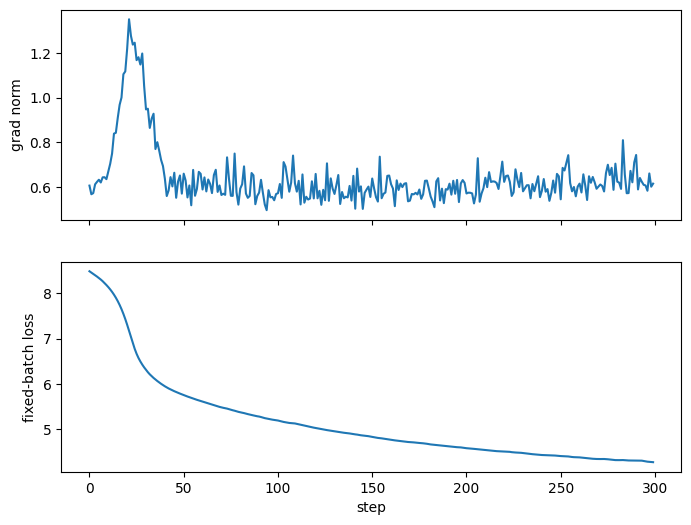

In [9]:
torch.manual_seed(0)
init_state = GPT(cfg).to(dev).state_dict()
fix_tok, fix_doc = fixed_batch("train", 8)
rows = run_tracked(step_correct, init_state, steps, fix_tok, fix_doc)
np.savetxt("results/tracked_seed0.csv", rows, delimiter=",",
           header="step,train_loss,gnorm,fixed_loss", comments="")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
ax1.plot(rows[:, 0], rows[:, 2]); ax1.set_ylabel("grad norm")
ax2.plot(rows[:, 0], rows[:, 3]); ax2.set_ylabel("fixed-batch loss"); ax2.set_xlabel("step")
fig.savefig("results/tracked_seed0.png", dpi=120, bbox_inches="tight")
plt.show()

In [10]:
gn, fl = rows[:, 2], rows[:, 3]
change = fl[1:] - fl[:-1]        # negative = this update lowered the loss

# after the early drop: grad norm jumps 10%+ while the loss still falls,
# and the very next update makes the loss go up
jumps = [s for s in range(60, len(change) - 1) if gn[s] > 1.1 * gn[s - 1]]
hits = [s for s in jumps if change[s] < 0 and change[s + 1] > 0]
print(f"grad norm jumps after step 60: {len(jumps)} | loss rose right after: {len(hits)}")
print("those steps:", hits)

def show(start, end):
    print("\nstep  gnorm  loss change")
    for s in range(start, end):
        print(f"{s:4d}  {gn[s]:.3f}  {change[s]:+.5f}" + ("  <- hit" if s in hits else ""))

show(19, 24)        # early drop: do they peak together?
show(276, 293)

grad norm jumps after step 60: 44 | loss rose right after: 2
those steps: [279, 289]

step  gnorm  loss change
  19  1.117  -0.12504
  20  1.219  -0.13315
  21  1.350  -0.13757
  22  1.276  -0.13489
  23  1.237  -0.12442

step  gnorm  loss change
 276  0.654  -0.00499
 277  0.686  -0.00466
 278  0.588  -0.00380
 279  0.705  -0.00143  <- hit
 280  0.624  +0.00068
 281  0.620  +0.00175
 282  0.592  -0.00003
 283  0.810  -0.00342
 284  0.656  -0.00395
 285  0.573  -0.00188
 286  0.573  -0.00072
 287  0.673  -0.00093
 288  0.622  -0.00065
 289  0.711  -0.00107  <- hit
 290  0.744  +0.00024
 291  0.590  +0.00113
 292  0.641  -0.00200


## Part 5: MFU

In [11]:
print("GPU:", torch.cuda.get_device_name(0) if dev == "cuda" else "cpu")
PEAK = 8.1e12        # one T4, FP32, from the datasheet

# weights used in matrix multiplies (embedding lookups don't count)
N_mm = sum(p.numel() for n, p in GPT(cfg).named_parameters()
           if p.dim() == 2 and not n.startswith(("tok_emb", "pos_emb")))

def flops_per_token(T):
    return 6 * N_mm + 12 * cfg.L * cfg.D * T

def sync():
    if dev == "cuda":
        torch.cuda.synchronize()

def make_data(b, lengths, n):
    stream = ShardStream(f"{SHARD_ROOT}/train", B=b, T=cfg.T, seed=0,
                         max_tokens=2_000_000).iter_batches()
    out = []
    for _ in range(n):
        mbs = []
        for t in lengths:
            x, d = next(stream)
            mbs.append((x[:, :t], d[:, :t]))
        out.append(mbs)
    return out

def measure(label, b, lengths, n_warm=5, n_meas=40):
    model = GPT(cfg).to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=3e-4)
    data = make_data(b, lengths, n_warm + n_meas)
    flops, tokens, model_time, t0 = 0, 0, 0.0, None
    for i, mbs in enumerate(data):
        if i == n_warm:
            sync()
            t0 = time.perf_counter()
            flops, tokens, model_time = 0, 0, 0.0
        opt.zero_grad(set_to_none=True)
        total = 0
        for x, d in mbs:
            tok, doc = to_t(x, d)
            attn, mask = make_masks(tok, doc)
            sync()
            t1 = time.perf_counter()
            loss, n = loss_fn(model(tok, attn), tok, mask)
            (loss * n).backward()
            sync()
            model_time += time.perf_counter() - t1
            total += n
            flops += tok.numel() * flops_per_token(tok.shape[1])
            tokens += tok.numel()
        for p in model.parameters():
            p.grad /= total
        opt.step()
    sync()
    dt = time.perf_counter() - t0
    print(f"{label:<18} {tokens/dt:>8,.0f} tok/s | MFU {100*flops/dt/PEAK:5.1f}% | "
          f"{1000*dt/n_meas:6.1f} ms/step | forward+backward {100*model_time/dt:.0f}%")
    del model, opt
    if dev == "cuda":
        torch.cuda.empty_cache()

measure("my run", 4, LENGTHS)
measure("B=4 T=256", 4, [256] * 4)
measure("B=16 T=256", 16, [256])
measure("B=64 T=256", 64, [256])
measure("B=128 T=256", 128, [256])

# longer sequences, same tokens per pass
for T, b in [(512, 32), (1024, 16), (2048, 8)]:
    cfg.T = T
    measure(f"B={b} T={T}", b, [T])
cfg.T = 256

GPU: Tesla T4
/kaggle/input/datasets/gona26/tinystories-data-540m/shards/train: 2 shards, 2,000,000 tokens, 7,812 blocks
my run               46,278 tok/s | MFU  11.4% |   33.9 ms/step | forward+backward 90%
/kaggle/input/datasets/gona26/tinystories-data-540m/shards/train: 2 shards, 2,000,000 tokens, 7,812 blocks
B=4 T=256            80,987 tok/s | MFU  20.3% |   50.6 ms/step | forward+backward 94%
/kaggle/input/datasets/gona26/tinystories-data-540m/shards/train: 2 shards, 2,000,000 tokens, 7,812 blocks
B=16 T=256           88,492 tok/s | MFU  22.2% |   46.3 ms/step | forward+backward 95%
/kaggle/input/datasets/gona26/tinystories-data-540m/shards/train: 2 shards, 2,000,000 tokens, 7,812 blocks
B=64 T=256           91,704 tok/s | MFU  23.0% |  178.7 ms/step | forward+backward 99%
/kaggle/input/datasets/gona26/tinystories-data-540m/shards/train: 2 shards, 2,000,000 tokens, 7,812 blocks
B=128 T=256          94,472 tok/s | MFU  23.7% |  346.9 ms/step | forward+backward 99%
/kaggle/input/da

## Part 6: 0.1 in fp32, bf16, fp8

In [12]:
def encode(x, e_bits, m_bits):
    # returns exponent field, mantissa field, stored value (x > 0, normal range)
    bias = 2 ** (e_bits - 1) - 1
    x = Fraction(x)
    k = math.floor(math.log2(x))
    slots = 2 ** m_bits
    mark = round((x / Fraction(2) ** k - 1) * slots)
    if mark == slots:               # rounded up to the next power of 2
        k, mark = k + 1, 0
    return k + bias, mark, (1 + Fraction(mark, slots)) * Fraction(2) ** k

formats = {"fp32": (8, 23), "bf16": (8, 7), "fp8": (4, 3)}
for name, (e, m) in formats.items():
    E, M, v = encode(Fraction(1, 10), e, m)
    print(f"{name:<5} 0 {E:0{e}b} {M:0{m}b}  stored {float(v):.12f}")

print("\nadd an update to a weight of 0.1")
for name, (e, m) in formats.items():
    w = encode(Fraction(1, 10), e, m)[2]
    for d in (3e-4, 3e-5):
        moved = encode(float(w) + d, e, m)[2] - w
        print(f"{name:<5} update {d:.0e} -> weight moves {float(moved):.3e}")

print("\nbf16 cast in torch:", torch.tensor(0.1).bfloat16().item())
if dev == "cuda":
    print("bf16 in hardware:", torch.cuda.is_bf16_supported(including_emulation=False))

fp32  0 01111011 10011001100110011001101  stored 0.100000001490
bf16  0 01111011 1001101  stored 0.100097656250
fp8   0 0011 101  stored 0.101562500000

add an update to a weight of 0.1
fp32  update 3e-04 -> weight moves 3.000e-04
fp32  update 3e-05 -> weight moves 3.000e-05
bf16  update 3e-04 -> weight moves 4.883e-04
bf16  update 3e-05 -> weight moves 0.000e+00
fp8   update 3e-04 -> weight moves 0.000e+00
fp8   update 3e-05 -> weight moves 0.000e+00

bf16 cast in torch: 0.10009765625
bf16 in hardware: False
